# Lab 2 – Deep Neural Networks
**ESIEA x SKEMA – SO Mathys, HOEGY Victor, ANDRIAMANAMIRIJA Fenosoa - Deep Learning (AI_INF5018)**

Goal: understand the architecture of two major kinds of neural networks, a standard deep neural network (DNN) and a convolutional neural network (CNN), on the MNIST handwritten-digit dataset.

In [3]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import SGDClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## Part 1 – Dataset

### Question 1 – Load MNIST: number of training/test images, classes and features

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images : 60000  (tensor shape (60000, 28, 28))
Test images     : 10000  (tensor shape (10000, 28, 28))
Classes         : 10  -> [0 1 2 3 4 5 6 7 8 9]
Features/image  : 784  (28 x 28 pixels)


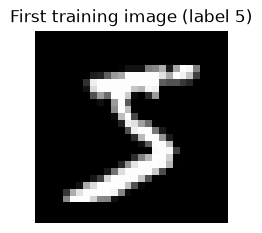

In [6]:
try:
    (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
except Exception as e:  # offline fallback: local copy of the same dataset (mnist.npz)
    print("keras download failed, using local mnist.npz:", type(e).__name__)
    d = np.load("mnist.npz")
    x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]

n_classes = len(np.unique(y_train))
n_features = int(np.prod(x_train.shape[1:]))
print(f"Training images : {x_train.shape[0]}  (tensor shape {x_train.shape})")
print(f"Test images     : {x_test.shape[0]}  (tensor shape {x_test.shape})")
print(f"Classes         : {n_classes}  -> {np.unique(y_train)}")
print(f"Features/image  : {n_features}  (28 x 28 pixels)")

plt.figure(figsize=(2.5, 2.5))
plt.imshow(x_train[0], cmap="gray"); plt.title(f"First training image (label {y_train[0]})"); plt.axis("off")
plt.show()

Answer : There are 60 000 training images and 10 000 test images, 10 classes (the digits 0 to 9), and each image has 28 * 28 * 1 = 784 features (one grey level per pixel).

### Question 2 – Number of training samples in each class

class 0: 5923 samples
class 1: 6742 samples
class 2: 5958 samples
class 3: 6131 samples
class 4: 5842 samples
class 5: 5421 samples
class 6: 5918 samples
class 7: 6265 samples
class 8: 5851 samples
class 9: 5949 samples


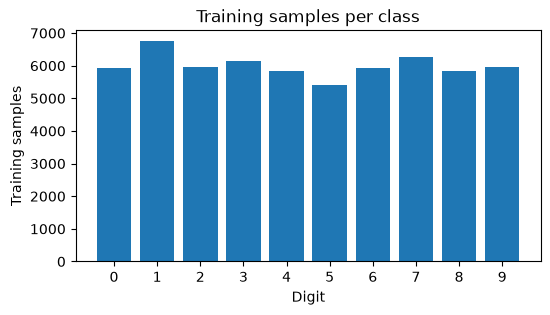

In [8]:
counts = np.bincount(y_train, minlength=10)
for digit, c in enumerate(counts):
    print(f"class {digit}: {c} samples")

plt.figure(figsize=(6, 3))
plt.bar(range(10), counts)
plt.xticks(range(10)); plt.xlabel("Digit"); plt.ylabel("Training samples"); plt.title("Training samples per class")
plt.show()

Answer: The dataset is almost balanced: each class has between roughly 5 400 and 6 750 images out of 60k. Class "1" is the most frequent and class "5" the least frequent, but the imbalance is mild, so plain accuracy is a reasonable metric.

### Question 3 – Preprocessing: flatten and normalise

In [10]:
x_train_flat = x_train.reshape(len(x_train), -1).astype("float32") / 255.0
x_test_flat  = x_test.reshape(len(x_test), -1).astype("float32") / 255.0
print("Flattened train:", x_train_flat.shape, "| test:", x_test_flat.shape)
print("Pixel range after normalisation:", x_train_flat.min(), "->", x_train_flat.max())

Flattened train: (60000, 784) | test: (10000, 784)
Pixel range after normalisation: 0.0 -> 1.0


Each image becomes a vector of length 28² = 784 (instead of a 28 × 28 matrix), and pixel values are divided by 255 so that they lie in [0, 1].

### Question 4 – Why is flattening a bad idea in principle?

Answer: Flattening an image in a 1D vector is a bad idea because we lose all the spacial contruction of it (2D, vertical horizontal neighbors) for the machine (CNN) it will be difficult to occur the convolutions steps on it. (pattern recognition and filter application).

- The network has to re-learn from data that neighbouring pixels are correlated, instead of having this prior built in.
- It uses many parameters (every pixel is connected to every neuron) and is not translation invariant: a digit shifted by a few pixels activates completely different inputs, so the same pattern at another position must be learned again.
- If we shuffled the pixel positions with the same permutation for all images, a dense network would perform exactly the same, which shows it does not exploit the image geometry at all.

## Part 2 – Linear model

### Question 5 – Ten networks with no hidden layer (`SGDClassifier`)
A neural network without hidden layers is a linear model (one weight matrix + softmax / one-vs-rest). As in the previous lab, we train it with `SGDClassifier`. Each of the 10 runs uses a different random seed (different weight initialisation and data shuffling), then we report the mean and standard deviation of the test accuracy.

In [15]:
accs = []
for run in range(10):
    clf = SGDClassifier(random_state=run, max_iter=50, tol=1e-3, n_jobs=-1)
    clf.fit(x_train_flat, y_train)
    acc = clf.score(x_test_flat, y_test)
    accs.append(acc)
    print(f"run {run+1:2d}: test accuracy = {acc:.4f}")

accs = np.array(accs)
lin_mean, lin_std = accs.mean(), accs.std()
print(f"\nLinear model (SGDClassifier), 10 runs: mean = {lin_mean:.4f}, std = {lin_std:.4f}")

run  1: test accuracy = 0.9179
run  2: test accuracy = 0.9198
run  3: test accuracy = 0.9177
run  4: test accuracy = 0.9163
run  5: test accuracy = 0.9136
run  6: test accuracy = 0.9155
run  7: test accuracy = 0.9155
run  8: test accuracy = 0.9170
run  9: test accuracy = 0.9061
run 10: test accuracy = 0.9161

Linear model (SGDClassifier), 10 runs: mean = 0.9155, std = 0.0035


**Why is it useful?**

1. It gives a **baseline**: any deep model must beat this linear classifier to justify its extra complexity and training cost. If it did not, the added layers would bring nothing.
2. The **standard deviation** quantifies the run-to-run randomness (initialisation and shuffling). It tells us how large an accuracy difference must be before we can say a model is really better rather than just luckier.
3. It also shows how much of MNIST is already solvable with a **linear decision boundary**, so we know what the hidden layers and convolutions have to improve on.

## Part 3 – A deep neural network (Keras)

### Question 6 – Build and compile the DNN

In [16]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

dnn = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(512), layers.ReLU(),
    layers.Dense(256), layers.ReLU(),
    layers.Dense(128), layers.ReLU(),
    layers.Dense(64),  layers.ReLU(),
    layers.Dense(32),  layers.ReLU(),
    layers.Dense(16),  layers.ReLU(),
    layers.Dense(10),
    layers.Softmax(),
], name="dnn")

dnn.compile(loss="sparse_categorical_crossentropy",
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            metrics=["accuracy"])

### Question 7 – Why a Softmax activation at the end?

Answer: The last Dense layer outputs 10 raw scores (logits) that can be any real number. Softmax turns them into a probability distribution over the 10 classes: every output is in (0, 1) and they sum to 1, so output *k* can be read as "probability that the image is the digit *k*". This is what the categorical cross-entropy loss expects (it compares this distribution to the true label), and the predicted class is simply the argmax. Softmax is also differentiable, which makes training with gradient descent possible.

### Question 8 – Fit the DNN (10 epochs, batch size 60) and print the test accuracy

In [17]:
hist_dnn = dnn.fit(x_train_flat, y_train, epochs=10, batch_size=60, validation_split=0.0, verbose=2)
dnn_loss, dnn_acc = dnn.evaluate(x_test_flat, y_test, verbose=0)
print(f"\nDNN test accuracy: {dnn_acc:.4f}  (test loss {dnn_loss:.4f})")

Epoch 1/10
1000/1000 - 13s - 13ms/step - accuracy: 0.9216 - loss: 0.2630
Epoch 2/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9717 - loss: 0.0956
Epoch 3/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9792 - loss: 0.0670
Epoch 4/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9840 - loss: 0.0528
Epoch 5/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9876 - loss: 0.0429
Epoch 6/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9889 - loss: 0.0369
Epoch 7/10
1000/1000 - 11s - 11ms/step - accuracy: 0.9905 - loss: 0.0320
Epoch 8/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9918 - loss: 0.0283
Epoch 9/10
1000/1000 - 9s - 9ms/step - accuracy: 0.9932 - loss: 0.0242
Epoch 10/10
1000/1000 - 10s - 10ms/step - accuracy: 0.9929 - loss: 0.0236

DNN test accuracy: 0.9771  (test loss 0.0940)


### Question 9 – Summary and number of parameters

In [8]:
dnn.summary()

# check the numbers by hand
sizes = [784, 512, 256, 128, 64, 32, 16, 10]
total = 0
for i in range(len(sizes) - 1):
    p = sizes[i] * sizes[i+1] + sizes[i+1]
    total += p
    print(f"Dense {sizes[i]:>3} -> {sizes[i+1]:>3}: {sizes[i]}*{sizes[i+1]} weights + {sizes[i+1]} biases = {p:,}")
print("Total:", f"{total:,}", "| Keras says:", f"{dnn.count_params():,}")
assert total == dnn.count_params()

Model: "dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,731,536 (6.61 MB)

 Trainable params: 577,178 (2.20 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,154,358 (4.40 MB)

Dense 784 -> 512: 784*512 weights + 512 biases = 401,920
Dense 512 -> 256: 512*256 weights + 256 biases = 131,328
Dense 256 -> 128: 256*128 weights + 128 biases = 32,896
Dense 128 ->  64: 128*64 weights + 64 biases = 8,256
Dense  64 ->  32: 64*32 weights + 32 biases = 2,080
Dense  32 ->  16: 32*16 weights + 16 biases = 528
Dense  16 ->  10: 16*10 weights + 10 biases = 170
Total: 577,178 | Keras says: 577,178


**How to read the table.**
- There is a total of 577,178 parameters, which is very high for dense model.
- Each row is a layer, with the output shape (`None` is the batch dimension, whose size is not fixed) and the number of parameters.
- A Dense layer with *n_in* inputs and *n_out* neurons has *n_in × n_out* weights plus *n_out* biases, i.e. *n_in × n_out + n_out* parameters. For example the first layer has 784 * 512 + 512 = 401 920 parameters.
- The ReLU and Softmax layers have 0 parameters: they apply a fixed function and learn nothing.

### Question 10 – Save the model on the computer

In [18]:
dnn.save("dnn_mnist.keras")
print("Saved:", os.path.abspath("dnn_mnist.keras"), f"({os.path.getsize('dnn_mnist.keras')/1e6:.1f} MB)")
# it can be reloaded later with: keras.models.load_model("dnn_mnist.keras")

Saved: c:\Users\somat\OneDrive - Groupe ESIEA\Desktop\5A\deeplearning\LAB2\dnn_mnist.keras (7.0 MB)


## Part 4 – A Convolutional Neural Network

### Question 11 – Build and compile the CNN

In [19]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

x_train_img = x_train[..., np.newaxis].astype("float32") / 255.0   # (60000, 28, 28, 1)
x_test_img  = x_test[...,  np.newaxis].astype("float32") / 255.0
print("CNN input shape:", x_train_img.shape)

cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=5, strides=1, padding="same"),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2, strides=2, padding="valid"),
    layers.Conv2D(64, kernel_size=3, strides=1, padding="same"),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2, strides=2, padding="valid"),
    layers.Flatten(),
    layers.Dense(128),
    layers.ReLU(),
    layers.Dense(10),
    layers.Softmax(),
], name="cnn")

cnn.compile(loss="sparse_categorical_crossentropy",
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            metrics=["accuracy"])
cnn.summary()

CNN input shape: (60000, 28, 28, 1)


Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,154 (1.61 MB)

 Trainable params: 422,154 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

There is 422, 154 parameters which is less than the DNN, approximatively 4x lighter than the dnn.

### Question 12 – Fit the CNN (batch size 128, 5 epochs) and print the test accuracy

In [20]:
hist_cnn = cnn.fit(x_train_img, y_train, epochs=5, batch_size=128, verbose=2)
cnn_loss, cnn_acc = cnn.evaluate(x_test_img, y_test, verbose=0)
print(f"\nCNN test accuracy: {cnn_acc:.4f}  (test loss {cnn_loss:.4f})")

Epoch 1/5
469/469 - 26s - 56ms/step - accuracy: 0.9384 - loss: 0.2041
Epoch 2/5
469/469 - 27s - 57ms/step - accuracy: 0.9835 - loss: 0.0541
Epoch 3/5
469/469 - 39s - 82ms/step - accuracy: 0.9887 - loss: 0.0381
Epoch 4/5
469/469 - 48s - 103ms/step - accuracy: 0.9912 - loss: 0.0292
Epoch 5/5
469/469 - 70s - 149ms/step - accuracy: 0.9935 - loss: 0.0227

CNN test accuracy: 0.9910  (test loss 0.0284)


### Question 13 – Total number of parameters of the CNN

In [12]:
conv1 = 5*5*1*32 + 32
conv2 = 3*3*32*64 + 64
flat  = 7*7*64
fc1   = flat*128 + 128
fc2   = 128*10 + 10
print(f"Conv2D(32, 5x5, 1 input channel): 5*5*1*32 + 32 biases = {conv1:,}")
print(f"Conv2D(64, 3x3, 32 input channels): 3*3*32*64 + 64 biases = {conv2:,}")
print(f"Flatten: 7*7*64 = {flat:,} values")
print(f"Dense 3136 -> 128: {flat}*128 + 128 = {fc1:,}")
print(f"Dense 128 -> 10  : 128*10 + 10 = {fc2:,}")
total_cnn = conv1 + conv2 + fc1 + fc2
print("Total:", f"{total_cnn:,}", "| Keras says:", f"{cnn.count_params():,}")
assert total_cnn == cnn.count_params()

Conv2D(32, 5x5, 1 input channel): 5*5*1*32 + 32 biases = 832
Conv2D(64, 3x3, 32 input channels): 3*3*32*64 + 64 biases = 18,496
Flatten: 7*7*64 = 3,136 values
Dense 3136 -> 128: 3136*128 + 128 = 401,536
Dense 128 -> 10  : 128*10 + 10 = 1,290
Total: 422,154 | Keras says: 422,154


**Explanation.**

- **Conv2D** parameters = (kernel height × kernel width × input channels + 1 bias) × number of filters. They do **not** depend on the image size, because each filter is **shared** across all positions. Conv1 has 832 parameters and Conv2 has 18 496.
- **MaxPooling2D** and **ReLU** have **0 parameters**. Each pooling halves the spatial size: 28 × 28 → 14 × 14 → 7 × 7 (`padding="same"` in the convolutions keeps the size, only the pooling reduces it).
- **Flatten** has 0 parameters; it turns the 7 × 7 × 64 feature maps into a vector of 3 136 values.
- The first **Dense** layer holds almost all of the parameters (401 536 out of 422 154, about 95 %) because it connects each of the 3 136 values to 128 neurons.
- Overall, the CNN has about **422 k** parameters versus **577 k** for the DNN: it is **smaller**, yet it should be more accurate, since the convolutions use the 2D structure and weight sharing instead of connecting every pixel to every neuron.

### Question 14 – First 5 test images with their predicted class

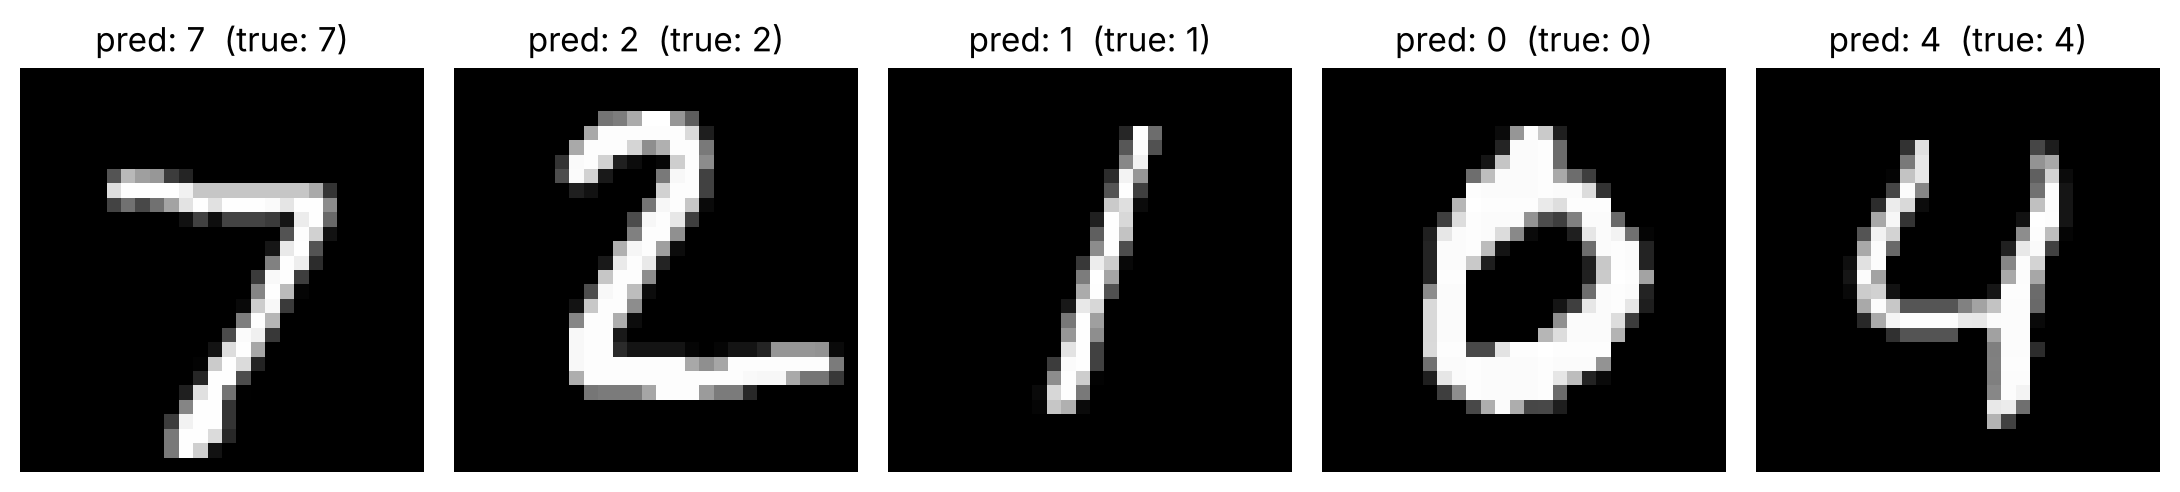

Predicted: [7 2 1 0 4] | True: [7 2 1 0 4]


In [13]:
probs = cnn.predict(x_test_img[:5], verbose=0)
pred = probs.argmax(axis=1)

fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
for i, ax in enumerate(axes):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"pred: {pred[i]}  (true: {y_test[i]})")
plt.tight_layout(); plt.show()
print("Predicted:", pred, "| True:", y_test[:5])

Datas from dataset (train / test) are very satisfying, every digit is well predicted. This result perfectly illustrate the accuracy that we found during the fitting.

### Question 15 – Predict on new images
Load the four images, resize them to the shape the network accepts (28 × 28, one grey channel), normalise them in the same way as the training data (values in [0, 1], white digit on black background like MNIST), predict their label and display it next to each image.

Put the four image files in a folder named `digits/` next to this notebook (any format Pillow reads: png, jpg...). The cell skips gracefully if the folder is empty.

In [27]:
from PIL import Image, ImageOps, ImageFilter

folder = "."                     # dossier qui contient les photos num_*.webp
out_folder = "digits"            # les images 28x28 converties seront enregistrées ici
os.makedirs(out_folder, exist_ok=True)

def to_mnist(path):
    """Transforme une photo de chiffre manuscrit en image 28x28 au format MNIST."""
    img = Image.open(path).convert("L")                    # 1. niveaux de gris
    img = ImageOps.invert(img)                             # 2. MNIST = chiffre blanc sur fond noir
    img = img.filter(ImageFilter.GaussianBlur(2))          #    lisse le grain de la photo

    a = np.asarray(img, dtype="float32")                   # 3. seuillage : on garde l'encre, le papier passe à 0
    mask = a > a.mean() + 2 * a.std()                      #    (élimine aussi l'ombre et le fond gris)
    img = Image.fromarray((mask * 255).astype("uint8"))

    img = img.crop(img.getbbox())                          # 4. recadrage autour du chiffre

    k = max(3, (max(img.size) // 25) | 1)                  # 5. épaissit le trait (sinon il disparaît
    img = img.filter(ImageFilter.MaxFilter(k))             #    en passant de ~600 px à 20 px)

    w, h = img.size                                        # 6. réduit pour tenir dans 20x20
    s = 20 / max(w, h)                                     #    en gardant les proportions
    img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.Resampling.LANCZOS)

    canvas = Image.new("L", (28, 28), 0)                   # 7. centre dans un carré noir 28x28
    canvas.paste(img, ((28 - img.width) // 2, (28 - img.height) // 2))   # (marge de 4 px comme MNIST)
    return canvas

for file in sorted(os.listdir(folder)):
    if file.lower().endswith((".webp", ".jpg", ".jpeg", ".png")):
        img28 = to_mnist(os.path.join(folder, file))
        name = os.path.splitext(file)[0] + "_28x28.png"    # PNG : pas de perte de qualité contrairement au JPG
        img28.save(os.path.join(out_folder, name))
        print(f"{file} -> {out_folder}/{name}  {img28.size}")


num_2.webp -> digits/num_2_28x28.png  (28, 28)
num_5.webp -> digits/num_5_28x28.png  (28, 28)
num_5_final.webp -> digits/num_5_final_28x28.png  (28, 28)
num_7.webp -> digits/num_7_28x28.png  (28, 28)
num_8.webp -> digits/num_8_28x28.png  (28, 28)


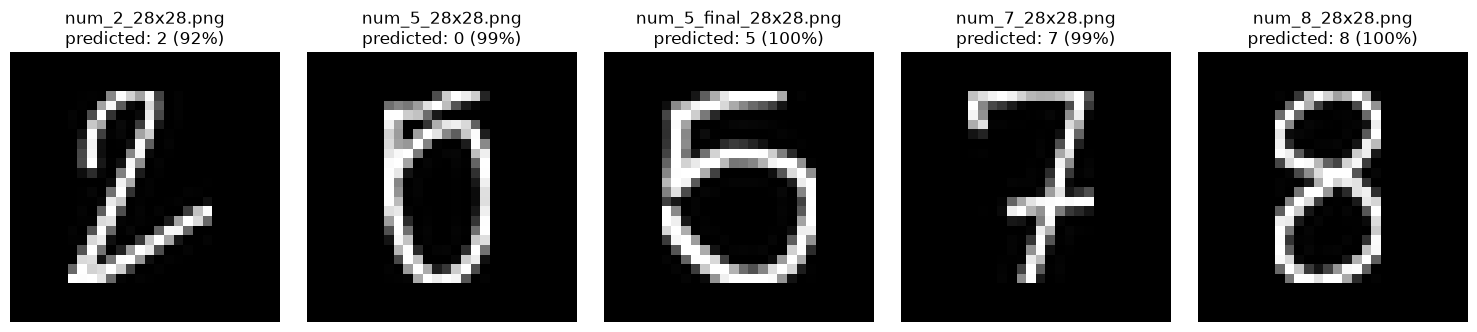

In [29]:
from PIL import Image, ImageOps

files = sorted(f for f in glob.glob("digits/*") if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".gif", ".webp")))
if not files:
    print("No image found in digits/ : add the four images there and re-run this cell.")
else:
    batch, shown = [], []
    for f in files:
        img = Image.open(f).convert("L")                      # grey level
        arr = np.asarray(img, dtype="float32")
        if arr.mean() > 127:                                   # dark digit on light paper -> invert like MNIST
            img = ImageOps.invert(img)
        img28 = img.resize((28, 28), Image.LANCZOS)            # network input size
        a = np.asarray(img28, dtype="float32") / 255.0         # same normalisation as training
        batch.append(a[..., np.newaxis]); shown.append(a)
    batch = np.stack(batch)
    preds = cnn.predict(batch, verbose=0)
    labels = preds.argmax(axis=1)

    fig, axes = plt.subplots(1, len(files), figsize=(3*len(files), 3.2))
    axes = np.atleast_1d(axes)
    for ax, a, lab, p, f in zip(axes, shown, labels, preds, files):
        ax.imshow(a, cmap="gray"); ax.axis("off")
        ax.set_title(f"{os.path.basename(f)}\npredicted: {lab} ({p.max():.0%})")
    plt.tight_layout(); plt.show()

Observations: Four of our image are correctly classified (2, 5, 7, 8) the most critical is the second image, according to us it looks more like a 6 but it is classified as a 0 with a confidence of 99%, this could be explained because the capacity of the model, the image size (28*28) and ambiguity of the shape. according to machine it looks like a 0 because of the rounded shape.

## Summary

In [15]:
print(f"{'Model':<32}{'Test accuracy':>15}")
print("-"*47)
print(f"{'Linear (SGDClassifier, mean/10)':<32}{lin_mean:>15.4f}   (std {lin_std:.4f})")
print(f"{'DNN (Keras, 10 epochs, bs 60)':<32}{dnn_acc:>15.4f}   ({dnn.count_params():,} params)")
print(f"{'CNN (Keras, 5 epochs, bs 128)':<32}{cnn_acc:>15.4f}   ({cnn.count_params():,} params)")

Model                             Test accuracy
-----------------------------------------------
Linear (SGDClassifier, mean/10)          0.9155   (std 0.0035)
DNN (Keras, 10 epochs, bs 60)            0.9793   (577,178 params)
CNN (Keras, 5 epochs, bs 128)            0.9905   (422,154 params)


After this lab we can conclude that the CNN is the best model for image classification task, it has less parameters than DNN and more accuracy than the linear SGDClassifier too.